In [2]:
import os
import shutil
import pandas as pd
import random
import matplotlib.pyplot as plt
from PIL import Image
import cv2
import numpy as np
from tqdm import tqdm

In [16]:
%pip install tqdm

     ---------------------------------------- 0.0/78.4 kB ? eta -:--:--
     ------------------------------------ --- 71.7/78.4 kB 3.8 MB/s eta 0:00:01
     ---------------------------------------- 78.4/78.4 kB 1.1 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.0.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
BASE_DIR = "data"

DATA_2019_DIR = os.path.join(BASE_DIR, "2019")
DATA_2020_DIR = os.path.join(BASE_DIR, "2020")

META_2019_PATH = os.path.join(DATA_2019_DIR, "metadata.csv")
META_2020_PATH = os.path.join(DATA_2020_DIR, "metadata.csv")

# Output
OUTPUT_DIR = "data_final"
OUTPUT_IMG_DIR = os.path.join(OUTPUT_DIR, "images")
BENIGN_DIR = os.path.join(OUTPUT_IMG_DIR, "benign")
MALIGNANT_DIR = os.path.join(OUTPUT_IMG_DIR, "malignant")


In [3]:
df_2019 = pd.read_csv(META_2019_PATH)
df_2020 = pd.read_csv(META_2020_PATH)

print("Jumlah data awal:")
print(f"2019: {len(df_2019)}")
print(f"2020: {len(df_2020)}")

Jumlah data awal:
2019: 25331
2020: 33126


C:\Users\Administrator\AppData\Local\Temp\ipykernel_16000\3282857423.py:2: DtypeWarning: Columns (14,21,23) have mixed types. Specify dtype option on import or set low_memory=False.
  df_2020 = pd.read_csv(META_2020_PATH)


In [4]:
df_2019["source_year"] = 2019
df_2020["source_year"] = 2020

In [5]:
df_all = pd.concat([df_2019, df_2020], ignore_index=True)

print("\nJumlah data setelah digabung:")
print(len(df_all))


Jumlah data setelah digabung:
58457


In [7]:
df_all = df_all[df_all["image_type"] == "dermoscopic"]

print("\nSetelah filter image_type = dermoscopic:")
print(len(df_all))


Setelah filter image_type = dermoscopic:
58457


In [8]:
df_all = df_all[df_all["diagnosis_1"].isin(["Benign", "Malignant"])]

print("\nSetelah filter diagnosis_1 (Benign & Malignant):")
print(df_all["diagnosis_1"].value_counts())
print("Total:", len(df_all))


Setelah filter diagnosis_1 (Benign & Malignant):
diagnosis_1
Benign       48529
Malignant     9057
Name: count, dtype: int64
Total: 57586


In [9]:
df_all = df_all[df_all["melanocytic"] == True]

print("\nSetelah filter melanocytic == True:")
print(df_all["diagnosis_1"].value_counts())
print("Total:", len(df_all))


Setelah filter melanocytic == True:
diagnosis_1
Benign       18020
Malignant     5094
Name: count, dtype: int64
Total: 23114


In [10]:
label_map = {
    "Benign": "benign",
    "Malignant": "malignant"
}

df_all["class_name"] = df_all["diagnosis_1"].map(label_map)
df_all["label"] = df_all["class_name"].map({"benign": 0, "malignant": 1})

print("\nDistribusi kelas final:")
print(df_all["class_name"].value_counts())


Distribusi kelas final:
class_name
benign       18020
malignant     5094
Name: count, dtype: int64


In [12]:
os.makedirs(BENIGN_DIR, exist_ok=True)
os.makedirs(MALIGNANT_DIR, exist_ok=True)

In [13]:
copied = 0
missing = 0

for _, row in df_all.iterrows():
    isic_id = row["isic_id"]
    year = row["source_year"]
    class_name = row["class_name"]

    if year == 2019:
        src_dir = DATA_2019_DIR
    else:
        src_dir = DATA_2020_DIR

    src_path = os.path.join(src_dir, f"{isic_id}.jpg")

    if class_name == "benign":
        dst_path = os.path.join(BENIGN_DIR, f"{isic_id}.jpg")
    else:
        dst_path = os.path.join(MALIGNANT_DIR, f"{isic_id}.jpg")

    if os.path.exists(src_path):
        shutil.copy(src_path, dst_path)
        copied += 1
    else:
        missing += 1

In [14]:
print("\n=== HASIL COPY GAMBAR ===")
print("Berhasil dicopy :", copied)
print("File tidak ditemukan :", missing)


=== HASIL COPY GAMBAR ===
Berhasil dicopy : 23114
File tidak ditemukan : 0


In [15]:
FINAL_META_PATH = os.path.join(OUTPUT_DIR, "metadata_final.csv")
df_all.to_csv(FINAL_META_PATH, index=False)

print("\nMetadata final disimpan di:", FINAL_META_PATH)


Metadata final disimpan di: data_final\metadata_final.csv


In [16]:
print("\n=== VALIDASI DATASET AKHIR ===")
print("Benign images :", len(os.listdir(BENIGN_DIR)))
print("Malignant images :", len(os.listdir(MALIGNANT_DIR)))
print("Total images :", len(os.listdir(BENIGN_DIR)) + len(os.listdir(MALIGNANT_DIR)))


=== VALIDASI DATASET AKHIR ===
Benign images : 18020
Malignant images : 5094
Total images : 23114


In [6]:
dataset_path = "data_final/images"
class_names = sorted(os.listdir(dataset_path))

print("Kelas yang tersedia:", class_names)

Kelas yang tersedia: ['benign', 'malignant']


In [7]:
print("\nJumlah gambar per kelas:")
total_images = 0

for cls in class_names:
    cls_dir = os.path.join(dataset_path, cls)
    if os.path.isdir(cls_dir):
        num_images = len([
            f for f in os.listdir(cls_dir)
            if f.lower().endswith(('.jpg', '.png', '.jpeg'))
        ])
        total_images += num_images
        print(f"- {cls}: {num_images} gambar")

print("Total seluruh gambar:", total_images)



Jumlah gambar per kelas:
- benign: 18020 gambar
- malignant: 5094 gambar
Total seluruh gambar: 23114


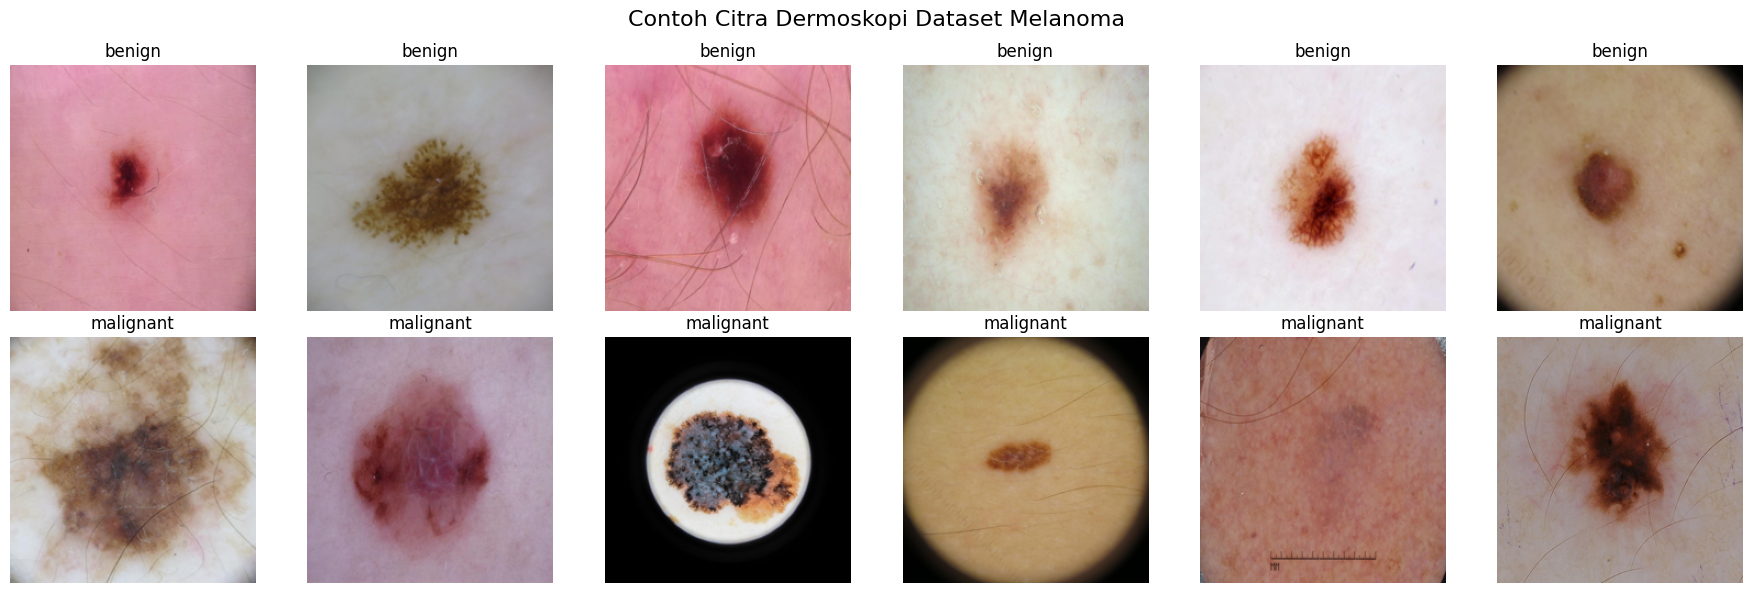

In [14]:
samples_per_class = 6
img_size = (224, 224)

plt.figure(figsize=(samples_per_class * 3, len(class_names) * 3))
plot_idx = 1

for cls in class_names:
    cls_dir = os.path.join(dataset_path, cls)
    images = [
        f for f in os.listdir(cls_dir)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    sampled_images = random.sample(images, samples_per_class)

    for img_name in sampled_images:
        img_path = os.path.join(cls_dir, img_name)
        img = Image.open(img_path).convert("RGB")
        img = img.resize(img_size)

        plt.subplot(len(class_names), samples_per_class, plot_idx)
        plt.imshow(img)
        plt.title(cls)
        plt.axis("off")

        plot_idx += 1

plt.suptitle("Contoh Citra Dermoskopi Dataset Melanoma", fontsize=16)
plt.tight_layout()
plt.show()

In [9]:
widths, heights = [], []

for cls in class_names:
    cls_dir = os.path.join(dataset_path, cls)
    for img_name in os.listdir(cls_dir)[:100]:
        img_path = os.path.join(cls_dir, img_name)
        img = Image.open(img_path)
        w, h = img.size
        widths.append(w)
        heights.append(h)

print("\nStatistik resolusi gambar (sampling):")
print(f"Lebar  min–max : {min(widths)} – {max(widths)}")
print(f"Tinggi min–max: {min(heights)} – {max(heights)}")
print(f"Rata-rata resolusi: {sum(widths)//len(widths)} x {sum(heights)//len(heights)}")


Statistik resolusi gambar (sampling):
Lebar  min–max : 722 – 3072
Tinggi min–max: 540 – 2304
Rata-rata resolusi: 1570 x 1180


# HAIR REMOVAL

In [3]:
img_path = "data_hair_removed\images\malignant\ISIC_0000043.jpg"

image = cv2.imread(img_path)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


In [4]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (17, 17))
blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel)
_, hair_mask = cv2.threshold(blackhat, 10, 255, cv2.THRESH_BINARY)
hair_removed = cv2.inpaint(
    image, hair_mask, inpaintRadius=1, flags=cv2.INPAINT_TELEA
)
hair_removed_rgb = cv2.cvtColor(hair_removed, cv2.COLOR_BGR2RGB)

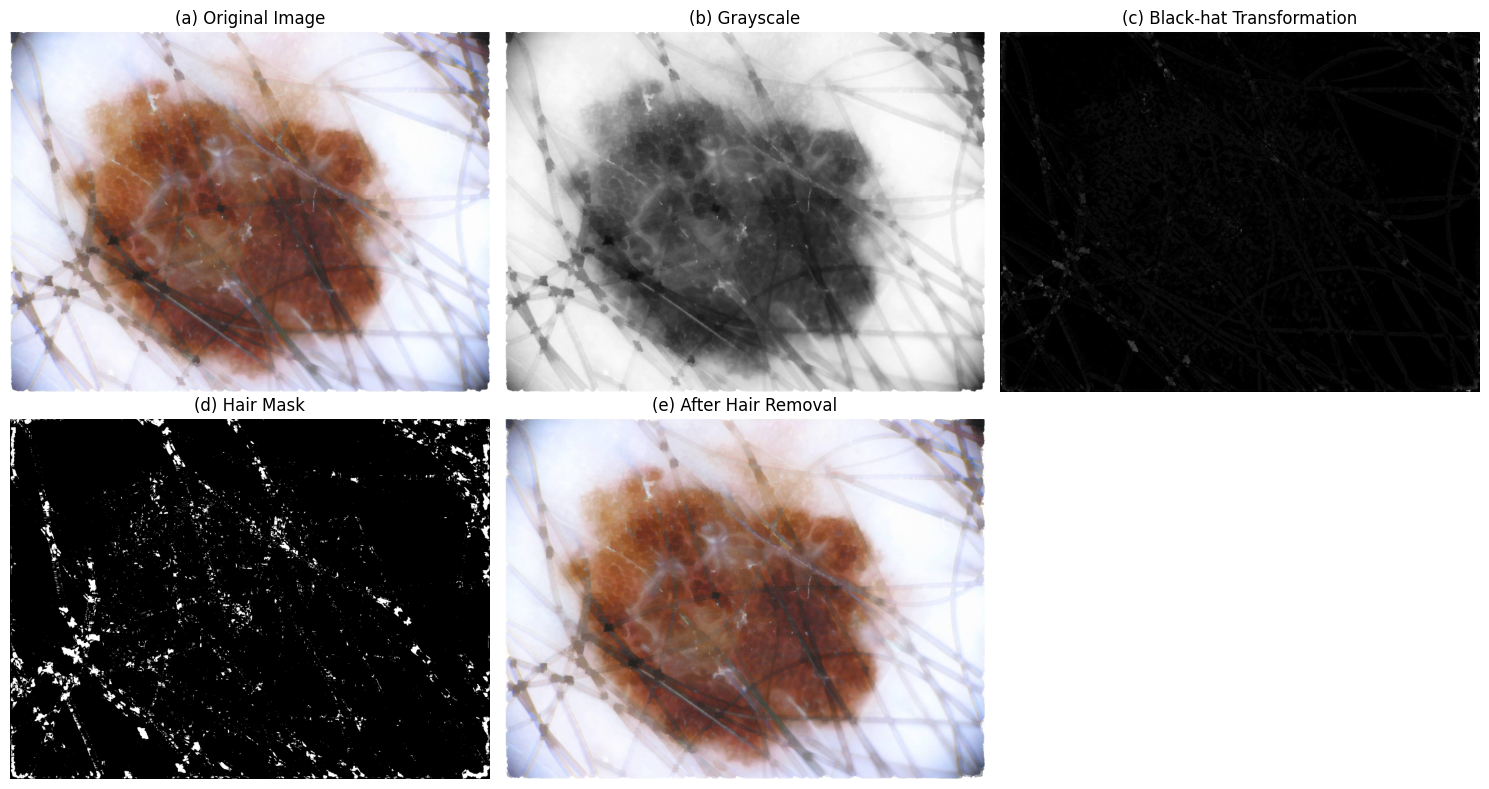

In [5]:
plt.figure(figsize=(15, 8))

plt.subplot(2, 3, 1)
plt.imshow(image_rgb)
plt.title("(a) Original Image")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(gray, cmap="gray")
plt.title("(b) Grayscale")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(blackhat, cmap="gray")
plt.title("(c) Black-hat Transformation")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(hair_mask, cmap="gray")
plt.title("(d) Hair Mask")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(hair_removed_rgb)
plt.title("(e) After Hair Removal")
plt.axis("off")

plt.tight_layout()
plt.show()


In [9]:
img_path = "data_final/images/malignant\ISIC_0000164.jpg"

image = cv2.imread(img_path)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


In [10]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (17, 17))
blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel)
_, hair_mask = cv2.threshold(blackhat, 10, 255, cv2.THRESH_BINARY)
hair_removed = cv2.inpaint(
    image, hair_mask, inpaintRadius=1, flags=cv2.INPAINT_TELEA
)
hair_removed_rgb = cv2.cvtColor(hair_removed, cv2.COLOR_BGR2RGB)

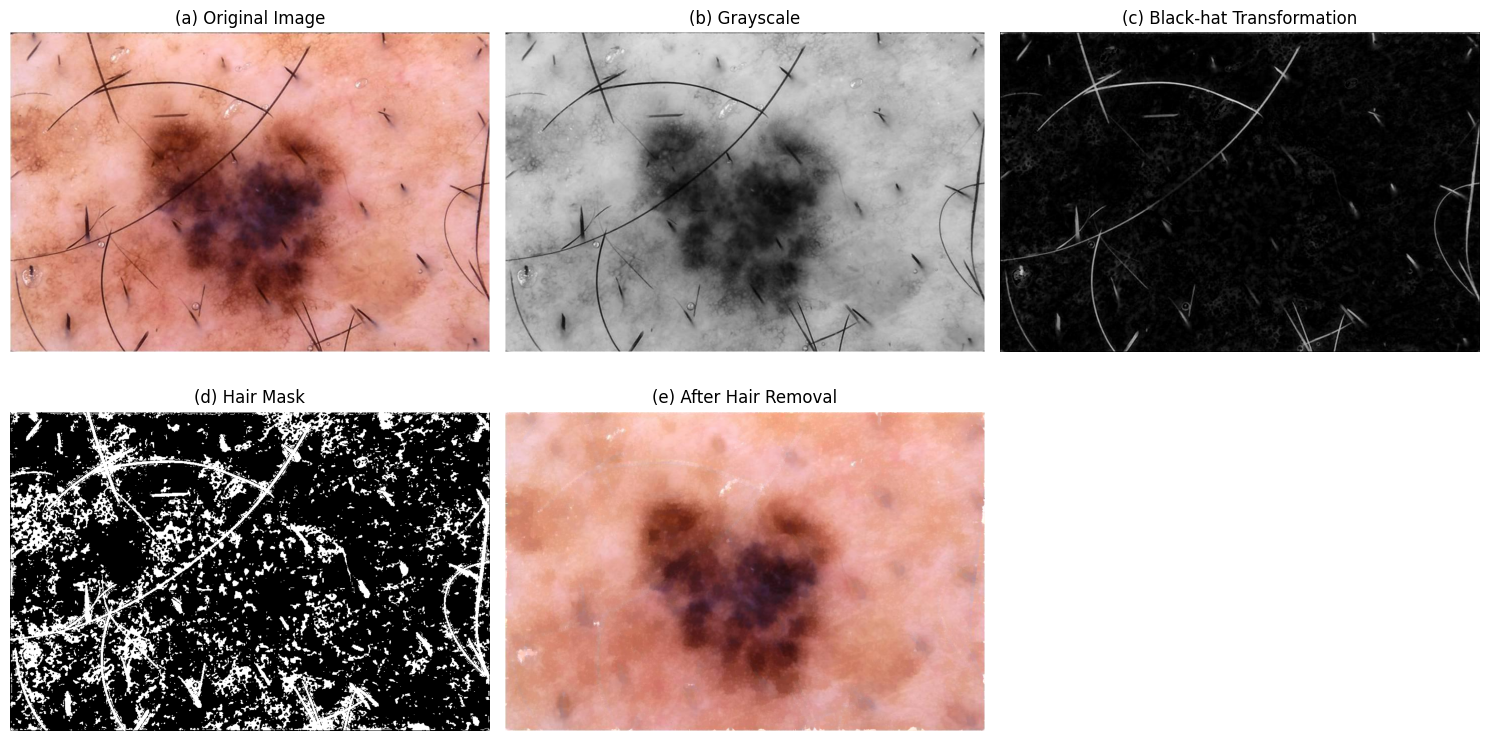

In [11]:
plt.figure(figsize=(15, 8))

plt.subplot(2, 3, 1)
plt.imshow(image_rgb)
plt.title("(a) Original Image")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(gray, cmap="gray")
plt.title("(b) Grayscale")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(blackhat, cmap="gray")
plt.title("(c) Black-hat Transformation")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(hair_mask, cmap="gray")
plt.title("(d) Hair Mask")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(hair_removed_rgb)
plt.title("(e) After Hair Removal")
plt.axis("off")

plt.tight_layout()
plt.show()


In [32]:
def remove_hair(image):
    """
    Digital hair removal using morphological black-hat and inpainting
    """
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Kernel untuk mendeteksi rambut
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (17, 17))

    # Black-hat operation
    blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel)

    # Threshold untuk mendapatkan mask rambut
    _, hair_mask = cv2.threshold(
        blackhat, 10, 255, cv2.THRESH_BINARY
    )

    # Inpainting untuk menghilangkan rambut
    inpainted = cv2.inpaint(
        image, hair_mask, inpaintRadius=1, flags=cv2.INPAINT_TELEA
    )

    return inpainted


In [33]:
INPUT_DIR = "data_final/images"
OUTPUT_DIR = "data_hair_removed/images"

classes = ["benign", "malignant"]

for cls in classes:
    os.makedirs(os.path.join(OUTPUT_DIR, cls), exist_ok=True)


In [34]:
total_images = 0

for cls in classes:
    input_cls_dir = os.path.join(INPUT_DIR, cls)
    output_cls_dir = os.path.join(OUTPUT_DIR, cls)

    images = [
        f for f in os.listdir(input_cls_dir)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    print(f"\nProcessing class '{cls}' ({len(images)} images)")

    for img_name in tqdm(images):
        img_path = os.path.join(input_cls_dir, img_name)
        out_path = os.path.join(output_cls_dir, img_name)

        image = cv2.imread(img_path)
        if image is None:
            continue

        hair_removed = remove_hair(image)
        cv2.imwrite(out_path, hair_removed)

        total_images += 1



Processing class 'benign' (18020 images)


100%|██████████| 18020/18020 [1:19:15<00:00,  3.79it/s]  



Processing class 'malignant' (5094 images)


100%|██████████| 5094/5094 [26:49<00:00,  3.17it/s] 


In [52]:
print("\nTotal images processed:", total_images)



Total images processed: 23114


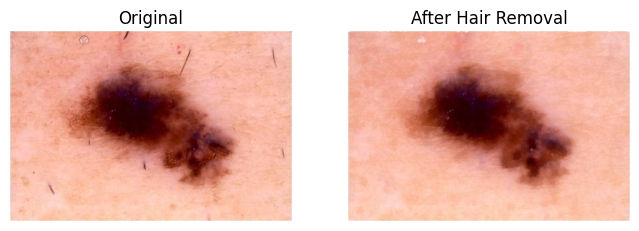

In [42]:
import matplotlib.pyplot as plt

sample_img = os.listdir(os.path.join(INPUT_DIR, "malignant"))[41]

orig = cv2.imread(os.path.join(INPUT_DIR, "malignant", sample_img))
proc = cv2.imread(os.path.join(OUTPUT_DIR, "malignant", sample_img))

orig = cv2.cvtColor(orig, cv2.COLOR_BGR2RGB)
proc = cv2.cvtColor(proc, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8,4))
plt.subplot(1,2,1)
plt.imshow(orig)
plt.title("Original")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(proc)
plt.title("After Hair Removal")
plt.axis("off")

plt.show()


<Figure size 800x1500 with 0 Axes>

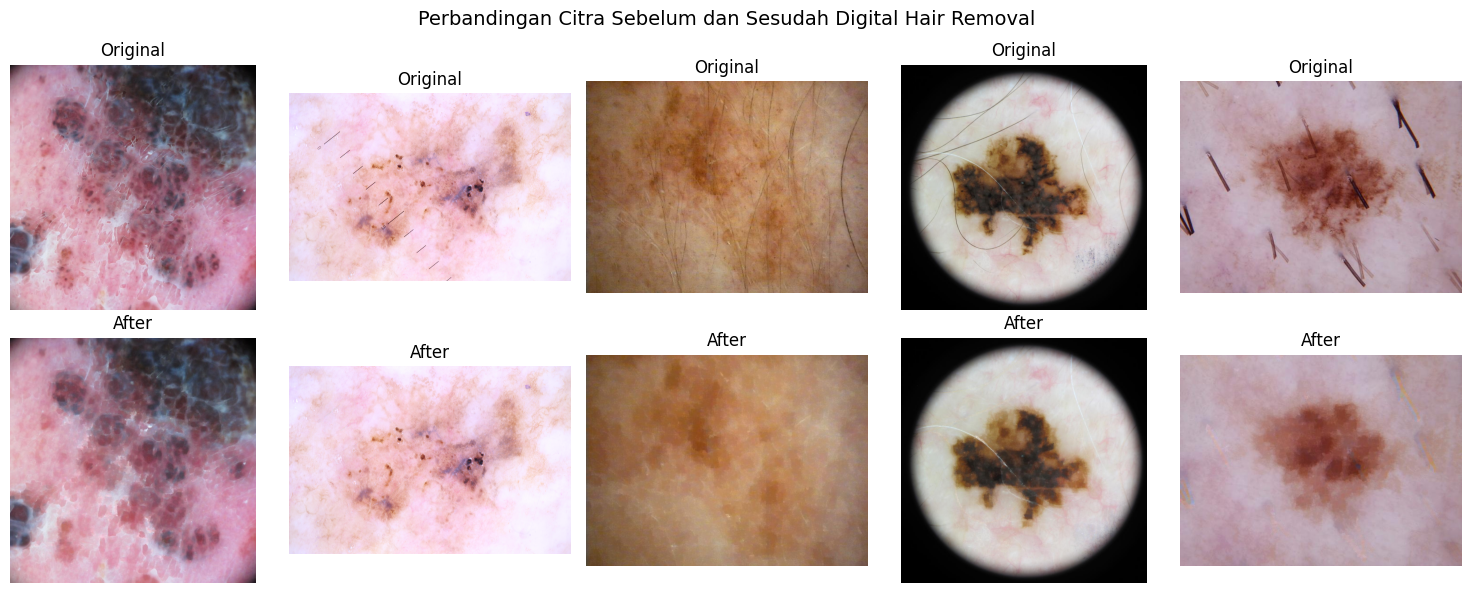

In [46]:
import os
import cv2
import random
import matplotlib.pyplot as plt

INPUT_DIR = "data_final/images"
OUTPUT_DIR = "data_hair_removed/images"

class_name = "malignant"   # bisa ganti "benign"
num_samples = 5            # jumlah contoh yang ingin ditampilkan

# Ambil daftar gambar
image_list = os.listdir(os.path.join(INPUT_DIR, class_name))
image_list = random.sample(image_list, num_samples)

plt.figure(figsize=(8, num_samples * 3))

plt.figure(figsize=(num_samples * 3, 6))

for i, img_name in enumerate(image_list):
    orig_path = os.path.join(INPUT_DIR, class_name, img_name)
    proc_path = os.path.join(OUTPUT_DIR, class_name, img_name)

    orig = cv2.imread(orig_path)
    proc = cv2.imread(proc_path)

    orig = cv2.cvtColor(orig, cv2.COLOR_BGR2RGB)
    proc = cv2.cvtColor(proc, cv2.COLOR_BGR2RGB)

    # Baris pertama: Original
    plt.subplot(2, num_samples, i + 1)
    plt.imshow(orig)
    plt.title("Original")
    plt.axis("off")

    # Baris kedua: After
    plt.subplot(2, num_samples, num_samples + i + 1)
    plt.imshow(proc)
    plt.title("After")
    plt.axis("off")

plt.suptitle(
    "Perbandingan Citra Sebelum dan Sesudah Digital Hair Removal",
    fontsize=14
)

plt.tight_layout()
plt.show()
